## Layout Modes
HTML has several distinct layout modes:

1. **Normal flow**: all elements are part of normal flow until you do something to take them out of it. Includes block and inline flows.
2. **Table**
3. **Positioned:** designed for positioning elements without much interaction with other elements.
4. **Multi-column:** designed for laying content out in columns as in a newspaper.
5. **Flexbox:** designed for laying out complex pages that can be resized smoothly.
6. **Grid:** designed for laying out elements relative to a fixed grid.

## Flow Layout
In this layout, every element will use a `display` value of either `inline`, `block`, or `inline-block`. This value governs how the flow layout algorithm will place the element. The default value depends on the tag; `div` elements are `block` by default, while `span`s are `inline`.

In flow layout, `block` elements stack in the *block* direction, and `inline` elements stack in the *inline* direction.

**Inline layout:** `inline` elements sit side by side on the same line and wrap to the next line when they run out of space. To shift things in the inline direction, we can use `margin-left` and `margin-right`, but we can't change its `width` or `height`. And in terms of the block direction, an inline element is where it is, and that's the end of the story. 

Elements like `<a>`, `<span>`, `<label>`, are all inline by default. An inline element’s line box height comes from `line-height`, so text lines have vertical breathing room even without padding or margin.

Inline elements wrap - this helps explain why certain CSS properties aren't available for inline elements. What would it even mean to increase the vertical margin on a shape like this? It's worth noting that it's still considered "one shape". If we add a border, we can see that we don't get 2 discrete rectangles, but rather a single rectangle cut in half and repositioned:

```html
<div class="container">
    <span>Hello all!&nbsp</span><span class="bordered">This shows how inline elements wrap to the next line.</span>
</div>
```
```css
.container {
    padding: 5px; 
    border:1px solid black; 
    width: 200px
}

.bordered {
    border:1px solid gray;
    background: yellow;
}
```

<div style="padding: 5px; border:1px solid black; width: 200px">
    <span>Hello all!&nbsp</span><span style="border:1px solid gray; background:yellow">This shows how inline elements wrap to the next line.</span>
</div>
<br>

**Inline-block:** allows us to drop a `block` element into an `inline` context. It's a block in inline's clothing. It's an element that internally acts like a `block` element, but externally acts like an `inline` element. The parent container will treat it as an `inline` element, since it's external. But the element itself can be styled like a `block`. One problem with `inline-block` elements are that they don’t wrap:

<div style="padding: 5px; border:2px solid pink; width: 300px; margin-bottom: 10px;">
    <h4>Inline</h4>
    <span>Hello all!&nbsp</span><span style="background:yellow;">This shows how inline elements wrap to the next line.</span>
</div>
<div style="padding: 5px; border:2px solid pink; width: 300px; margin-bottom: 10px;">
    <h4>Inline-Block</h4>
    <span>Hello all!&nbsp</span><span style="background:yellow; display:inline-block">This shows how inline elements wrap to the next line.</span>
</div>

`<img>` elements behave like inline block positioned. `<button>` also behaves similarly.

Images when displayed have this small empty space at the end:

<div style="border:2px solid pink; width: 400px">
	<img src="https://media.wired.com/photos/6ad9cd6aded54679300f97ae/master/w_1920,c_limit/Black-Hole-Star-cr-Mark-Belan-Lede.jpg" width="400px" height="200px">
</div>
<br>

One way to fix this is to set the `line-height` of the container `<div>` to 0:

<div style="border:2px solid pink; width: 400px; line-height: 0">
	<img src="https://media.wired.com/photos/6ad9cd6aded54679300f97ae/master/w_1920,c_limit/Black-Hole-Star-cr-Mark-Belan-Lede.jpg" width="400px" height="200px">
</div>
<br>

**Block:** is the default mode for most of the elements. When we place a `block` level element on the page, its content box expands to fill the entire available horizontal space. A heading might only need 150px to contain its letters, but if we put it in an 800px container, it will consume 800px of width. To force `width` of container to be equal its content:

```html
<h2>
    Heading with few words.
</h2>
```
```css
h2 {
    width: -moz-fit-content;
    width: fit-content;
    border: 2px dotted;
}
```

## Width and Height Algorithms
### Width Algorithms
When we use percentage-based widths, those percentages are **based on the parent element's content space**. If the `body` tag makes 400px of space available, any child with 100% width will become 400px wide, regardless of any other circumstances.

Block elements have a default `width` value of `auto`, not `100%`. `width: auto` works very similar to `margin: auto`; it's a hungry value that will grow as much as it's able to, but no more.

We have seen two keyword based measurement values `auto` and `fit-content`. There are others as well. When we set `width: min-content`, we're specifying that we want our content to become as small as it can, *based on the child contents*.  This is a totally different perspective: we aren't sizing based on the space made available by the parent, we're sizing based on the element's children! Consider the example:
```html
<h2>Some Big Headline</h2>

<style>
    h2 {
        background-color: yellow;
    }
</style>
```

<h2 style="background-color: yellow;">Some Big Headline</h2>
<br>

Now, if we update the CSS of `<h1>` tag:
```css
h2 {
    background-color: yellow;
    width: min-content;
}
```

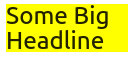
<br>

`width: max-content` is similar in principle, but it takes an opposite strategy: it never adds any line-breaks. The element's width will be the smallest value that contains the content, without breaking it up:
```html
<h1>An extremely long headline containing many words but with no context. It never adds any line-breaks. The element's width will be the smallest value that contains the content, without breaking it up</h1>

<style>
    h1 {
    	width: max-content;
    	background-color: yellow;
    }
</style>
```

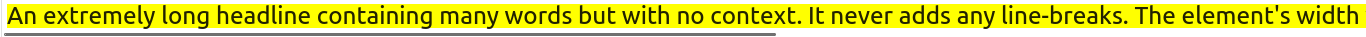

### Height Algorithms
In some ways, `height` works the same way as `width`. Setting an element to have a `height` of `50%` will force that item to take up half of the parent element's content area: no more, no less. In  other ways, they're quite different. The default "width" behaviour of a  block-level element is to fill all the available width, whereas the default "height" behaviour is to be as *small* as possible while fitting all of the element's content; it's closer to `width: min-content` than `width: auto`!

Setting height to a fixed value is generally a bad idea, we want height to dynamically expand or shrink as per its content. A classic situation is to have footer element at the bottom of the screen even if there isn’t enough content:  

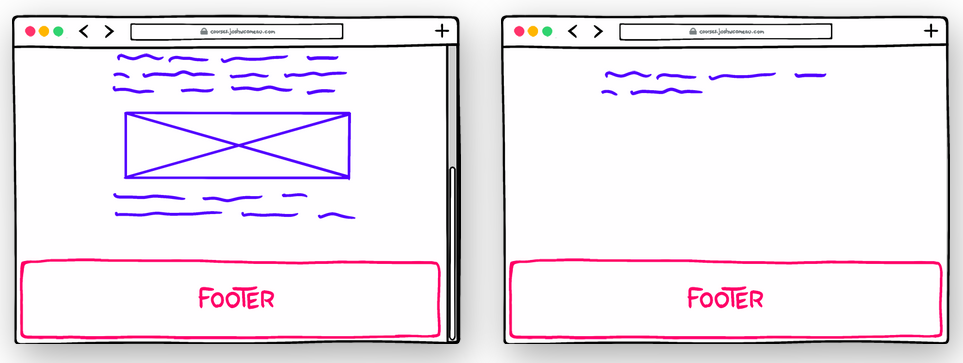

Setting `min-height: 100%` to wrapper element doesn’t work. One way to fix this is by setting html and body to 100%:

<div style="display: flex; align-items: flex-start; gap: 20px; width: 100%;">
<div style="padding: 10px">
    
```html
<div class="wrapper">
    <p>I fill the viewport now!</p>
</div>

<style>
    html, body {
      height: 100%;
    }
    
    .wrapper {
      min-height: 100%;
      border: solid;
    }
</style>
```

</div>

<div>
    <img src="./images/full-viewport.png">
</div>
    
</div>
<br>

What about the `vh` unit? The `vh` unit, is designed exactly for this purpose. If we set `height: 100vh`, the element will inherit its `height` from the viewport size. Unfortunately, this unit doesn't quite work the way we'd often like, because of mobile devices. When we scroll on a mobile device, the address bar and footer controls slide away, yielding their space to the content. This means that scrolling on a mobile device changes the viewport height.

To avoid this flickering UI issues, browsers like iOS Safari and Chrome Android will set `vh` equal to the maximum viewport height, after scrolling. This means that when the page first loads, `100vh` will actually be quite a bit taller than the viewable area. Therefore `height: 100%` method described above produces a better experience in most cases. The footer problem we described above, needs the above described `min-height` setting along with flexbox to work:

<div style="display: flex; align-items: flex-start; gap: 20px; width: 100%;">
<div style="padding: 10px">
    
```html
<div class="wrapper">
    <p>I fill the viewport!</p>
    <footer>I'm at the bottom</footer>
</div>

<style>
    html, body {
      height: 100%;
    }
    
    .wrapper {
      display: flex;
      flex-direction: column;
      min-height: 100%;
    }
    
    footer {
      border: solid hotpink;
      padding: 8px;
      margin-top: auto;
    }
</style>
````

</div>

<div>
    <img src="./images/vh-full-viewport.png">
</div>
    
</div>
<br>


## Positioned Layout
The defining feature of positioned layout is that items can overlap. The flow layout algorithm tries very hard to make sure that multiple elements never occupy the same pixels. With positioned layout, however, we can break out of the box.

We can opt into positioned layout using the `position` property. It can be set to `relative`, `absolute`, `fixed`, or `sticky`. The default value of the `position` property is `static`. Statically-positioned" elements means is that the elements are *not* using Positioned layout; they're using some other layout mode, like flow or flexbox or grid.

**Relative positioning:** `position: relative` does two things:
1. Constrains certain children
2. Enables additional CSS properties to be used: `top`, `left`, `right` and `bottom`

We can push element using the above mentioned additional properties. However we can do something similar with margins as well, so what is the difference? The big difference is that `position` doesn't impact layout. In terms of flow layout, the browser acts like the element is still in its original position. The displacement is purely cosmetic:

<div style="display: flex; gap: 20px;">
    <div style="border: 1px solid gray; padding: 10px">
        <h3>Natural Flow</h3>
        <div style="border: 2px solid pink; width: 50px; height: 50px; margin-bottom: 20px"></div>
        <div style="border: 2px solid black; width: 50px; height: 50px; margin-bottom: 20px"></div>
        <div style="border: 2px solid black; width: 50px; height: 50px; margin-bottom: 20px"></div>
    </div>
    <div style="border: 1px solid gray; padding: 10px">
        <h3>Top Margin</h3>
        <div style="border: 2px solid pink; width: 50px; height: 50px; margin-top: 50px; margin-bottom: 20px"></div>
        <div style="border: 2px solid black; width: 50px; height: 50px; margin-bottom: 20px"></div>
        <div style="border: 2px solid black; width: 50px; height: 50px; margin-bottom: 20px"></div>
    </div>
    <div style="border: 1px solid gray; padding: 10px">
        <h3>Relative Position</h3>
        <div style="border: 2px solid pink; width: 50px; height: 50px; position: relative; top: 50px; margin-bottom: 20px"></div>
        <div style="border: 2px solid black; width: 50px; height: 50px; margin-bottom: 20px"></div>
        <div style="border: 2px solid black; width: 50px; height: 50px; margin-bottom: 20px"></div>
    </div>
</div>
<br>
<div style="display: flex; gap: 20px;">
    <div style="border: 1px solid gray; padding: 10px; width: 300px;">
        <h3>Margin Left</h3>
        <div style="border: 2px solid pink; height: 50px; margin-left: 50px"></div>
    </div>
    <div style="border: 1px solid gray; padding: 10px; width: 300px;">
        <h3>Relative Position</h3>
        <div style="border: 2px solid pink; height: 50px; position: relative; left: 50px"></div>
    </div>
</div>
<br>

Relative positioning can be applied to both `block` and `inline` elements. This allows us to nudge `inline` elements in a way that isn't really possible otherwise.
```html
<p>
  This paragraph has some bolded text, and it <strong>appears to float</strong> a bit!
</p>

<style>
    strong {
        position: relative;
        top: -4px;
    }
</style>
```

<p>
  This paragraph has some bolded text, and it <strong style="position: relative; top: -4px;">appears to float</strong> a bit!
</p>
<br>

**Absolute positioning:** if we want to take an element out of this orderly flow, and stick it wherever we want, we need absolute positioning:
```html
<style>
  .pink.box {
    position: absolute;
    top: 0px;
    right: 0px;
    width: 75px;
    height: 75px;
    background: deeppink;
  }
</style>

<div class="pink box"></div>
<p>Hello World</p>
```

Absolutely-positioned elements are adjusted based on their container, not based on their in-flow position. If we don't give our absolute element an anchor, it sits in its default in-flow position.
```html
<style>
  .box {
    position: absolute;
    background: rgba(255,0,0,0.25);
  }
</style>

<p>
  Lorem Ipsum is simply dummy text of
  the printing and typesetting industry.
  <span class="box">Hello World</span>
  It has survived not only five centuries,
  but also the leap into electronic
  typesetting, remaining essentially
  unchanged.
</p>
```

<p style="padding: 10px; border: 1px solid gray">
  Lorem Ipsum is simply dummy text of
  the printing and typesetting industry.
  <span style="position: absolute; background: rgba(255,0,0,0.25);">Hello World</span>
  It has survived not only five centuries,
  but also the leap into electronic
  typesetting, remaining essentially
  unchanged.
</p>

Absolutely positioned elements grow as wide as the content while respecting the `top`, `bottom`, `left` and `right` properties. We can use absolute positioning with `auto` margin to center an element:
<div style="display: flex; align-items: flex-start; gap: 20px; width: 100%;">
<div style="padding: 10px">
    
```html
<div></div>

<style>
  div {
    background: teal;
    position: absolute;
    top: 0;
    bottom: 0;
    left: 0;
    right: 0;
    width: 200px;
    height:200px;
    margin: auto;
  }
</style>
```

</div>

<div>
    <img src="./images/full-centered.png">
</div>
    
</div>
<br>

One thing to notice is that the top, left, right and bottom properties for absolute elements are not relative to the containing box:
<div style="display: flex; align-items: flex-start; gap: 20px; width: 100%;">
<div style="padding: 10px">
    
```html
<div class="parent">
  <div class="child"></div>
</div>

<style>
  .parent {
    background: yellow;
    width: 200px;
    height:200px;
  }
  
  .child {
    position: absolute;
    background: aqua;
    width: 100px;
    height: 100px;
    bottom: 0;
    right: 0;
  }
</style>
```
</div>

<div>
    <img src="./images/absolute-html-anchored.png">
</div>
</div>
<br>

To fix this, we change positioning of the parent element to `relative`:
<div style="display: flex; align-items: flex-start; gap: 20px; width: 100%;">
<div style="padding: 10px">
    
```html
<div class="parent">
  <div class="child"></div>
</div>

<style>
  .parent {
	position: relative;
    background: yellow;
    width: 200px;
    height:200px;
  }
  
  .child {
    position: absolute;
    background: aqua;
    width: 100px;
    height: 100px;
    bottom: 0;
    right: 0;
  }
</style>
```
</div>

<div>
    <img src="./images/absolute-container-anchored.png">
</div>  
</div>
<br>

When deciding where to place an absolutely-positioned element, it crawls up through the tree, looking for a positioned ancestor. The first one it finds will provide the containing block. In the above case, we used `relative`, but it wil also work for `fixed`, `absolute` and `sticky`.

Absolute positiong can help with creating tooltips:
```html
<style>
  .tooltip {
    /* Hide the tooltip by default */
    display: none;
    background: white;
    border: 1px solid;
  }
  
  .tooltip-trigger:hover .tooltip {
    display: block;
  }
</style>

<p>The traditional Japanese tea ceremony centers on the preparation, serving, and drinking of <a href="/" class="tooltip-trigger">matcha<span class="tooltip">A concentrated, powdered form of green tea</span></a> as hot tea.</p>
```

<video style="padding: 10px; border: 1px solid gray" src="./images/basic-tooltip.webm" controls width="600"></video>

We make some adjustment to the above starting point:
```css
.tooltip-trigger {
    display: inline-block;
    position: relative;
}

.tooltip {
    /* Hide the tooltip by default */
    display: none;
    background: white;
    border: 1px solid;
    position: absolute;
    min-width: 150px;
    color: black;
    padding: 8px;
    font-size: 0.85rem;
}

.tooltip-trigger:hover .tooltip {
    display: block;
}
```

<video style="padding: 10px; border: 1px solid gray" src="./images/better-tooltip.webm" controls width="600"></video>